A crystal structure (chapter 11) is a single snapshot, but a real protein is in constant thermal motion: side chains rotate, loops wave, pockets open and close, water molecules shuttle in and out. That motion determines how a drug finds its pocket, how tightly it binds, and whether a "hidden" pocket ever appears. **Molecular dynamics** (MD) simulates this by computing the forces on every atom and stepping them forward in time, over and over, millions of times. This chapter builds a real MD simulator from first principles, so you understand exactly what the big packages (GROMACS, AMBER, OpenMM) are doing when they simulate a protein–drug system.

:::eli5
Molecular dynamics is a physics movie of molecules. Every atom pushes and pulls on its neighbours, atoms that get too close shove apart, nearby atoms gently attract. If you know all those pushes, Newton's law (force makes things accelerate) tells you how each atom moves in the next tiny instant. Compute the forces, nudge every atom a tiny step, recompute, nudge again, do it a billion times, and you get a movie of the molecule wobbling and flexing, from which you can measure how it really behaves.
:::

## The idea: forces, then Newton

MD rests on one equation you already know, Newton's second law, applied to every atom:

:::math
$$\mathbf{F}_i = m_i \mathbf{a}_i = m_i \frac{d^2 \mathbf{r}_i}{dt^2}.$$

The force on atom $i$ comes from a **potential energy** function $U(\mathbf{r}_1, \dots, \mathbf{r}_N)$ that describes how the atoms interact: $\mathbf{F}_i = -\nabla_i U$. Given the forces, we integrate the equations of motion forward in tiny time steps. That is the whole method; everything else is detail about $U$ and how to integrate accurately.
:::

Let's build it in 2D with simple atoms. Our only interaction will be the **Lennard-Jones** potential, which captures the two essential features of how neutral atoms interact (prerequisite P2): a weak attraction at medium range (van der Waals) and a hard repulsion when atoms overlap (electron clouds can't interpenetrate).

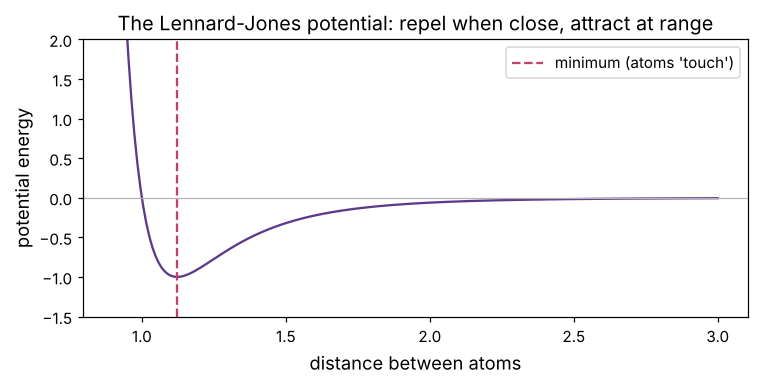

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from pathlib import Path
import warnings; warnings.filterwarnings("ignore")

mpl.rc("figure", dpi=110); mpl.rc("axes", labelsize=12, titlesize=13)
IMAGES = Path("images"); IMAGES.mkdir(exist_ok=True)
def save_fig(name):
    plt.tight_layout(); plt.savefig(IMAGES / f"{name}.png", dpi=150, bbox_inches="tight")
R = {}
rng = np.random.default_rng(0)

def lj_potential(r):
    return 4 * (r ** -12 - r ** -6)                 # in reduced units (epsilon = sigma = 1)

r = np.linspace(0.9, 3, 200)
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(r, lj_potential(r), color="#5b3a8c")
ax.axhline(0, color="0.7", lw=0.8); ax.axvline(2 ** (1/6), color="#c2416b", ls="--", label="minimum (atoms 'touch')")
ax.set_ylim(-1.5, 2); ax.set_xlabel("distance between atoms"); ax.set_ylabel("potential energy")
ax.set_title("The Lennard-Jones potential: repel when close, attract at range"); ax.legend()
save_fig("lj"); plt.show()

![Figure 12-1. The Lennard-Jones potential. Atoms repel steeply when too close (the wall on the left), sit happily at the minimum distance, and attract weakly further out. This simple curve captures van der Waals interactions.](images/lj.png)

## Integrating the motion: velocity Verlet

Given forces, we need to step positions and velocities forward in time. The naive Euler method accumulates error and lets energy drift to infinity. MD uses the **velocity Verlet** integrator, which is time-reversible and conserves energy well:

:::math
1. half-step the velocity: $\mathbf{v} \leftarrow \mathbf{v} + \tfrac12 \mathbf{a}\,\Delta t$
2. full-step the position: $\mathbf{r} \leftarrow \mathbf{r} + \mathbf{v}\,\Delta t$
3. recompute forces/acceleration at the new positions
4. half-step the velocity again: $\mathbf{v} \leftarrow \mathbf{v} + \tfrac12 \mathbf{a}\,\Delta t$
:::

Here is a complete MD engine. We place atoms on a lattice (random positions would have overlaps and explode), give them random velocities, and use **periodic boundaries** (an atom leaving one side re-enters the other) so a small box mimics bulk material.

In [2]:
N, L, dt = 64, 9.0, 0.004
def init():
    g = int(np.ceil(np.sqrt(N)))
    xs = np.linspace(0.5, L - 0.5, g)
    pos = np.array([[x, y] for x in xs for y in xs])[:N]
    vel = rng.standard_normal((N, 2)); vel -= vel.mean(0)         # zero net momentum
    return pos, vel * 0.6

def forces(pos):
    F = np.zeros_like(pos); PE = 0.0
    for i in range(N):
        d = pos[i] - pos
        d -= L * np.round(d / L)                                   # minimum-image (periodic)
        r2 = (d ** 2).sum(1); r2[i] = np.inf
        mask = r2 < 9.0                                            # cutoff for efficiency
        inv6 = (1.0 / r2[mask]) ** 3; inv12 = inv6 ** 2
        fmag = (48 * inv12 - 24 * inv6) / r2[mask]
        F[i] += (fmag[:, None] * d[mask]).sum(0)
        PE += 4 * (inv12 - inv6).sum() * 0.5                       # 0.5 to not double-count pairs
    return F, PE

def run(steps, thermostat=None):
    pos, vel = init()
    F, PE = forces(pos)
    energies, temps = [], []
    for step in range(steps):
        vel += 0.5 * dt * F
        pos = (pos + dt * vel) % L
        F, PE = forces(pos)
        vel += 0.5 * dt * F
        KE = 0.5 * (vel ** 2).sum()
        T = KE / N                                                # temperature ~ average kinetic energy
        if thermostat is not None:                                # rescale velocities toward target T
            vel *= np.sqrt(1 + 0.05 * (thermostat / (T + 1e-9) - 1))
        energies.append(KE + PE); temps.append(T)
    return np.array(energies), np.array(temps), pos, vel

energies, temps, pos, vel = run(2000)
drift = energies.std() / abs(energies.mean())
print(f"energy drift over 2000 steps: {drift:.2%} (should be tiny)")
R["drift"] = f"{drift:.2%}"

energy drift over 2000 steps: 0.03% (should be tiny)


## The crucial test: energy conservation

An isolated system conserves total energy. If our integrator is correct, kinetic plus potential energy should stay constant (apart from tiny fluctuations), even as energy sloshes between motion and arrangement. This is the single most important check in MD: a drifting energy means a bug or too large a time step.

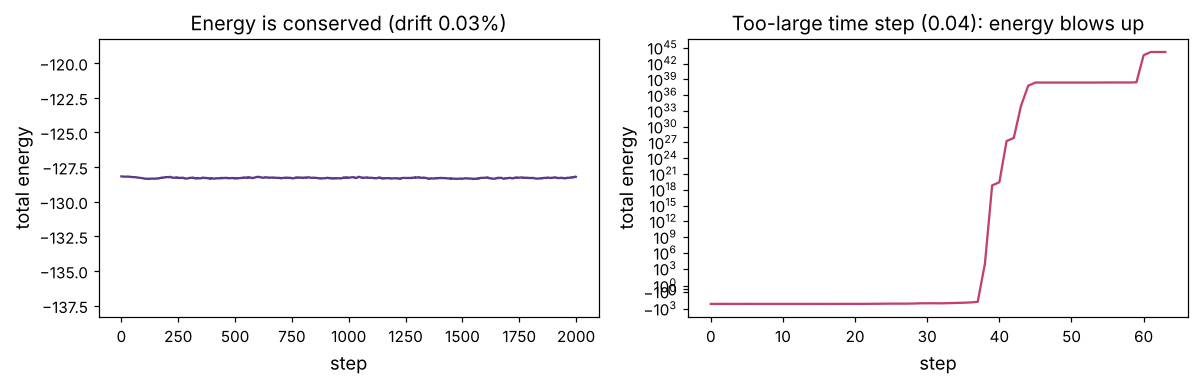

large-step energy: blew up


In [3]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
axs[0].plot(energies, color="#5b3a8c")
axs[0].set_xlabel("step"); axs[0].set_ylabel("total energy"); axs[0].set_title(f"Energy is conserved (drift {drift:.2%})")
axs[0].set_ylim(energies.mean() - 10, energies.mean() + 10)
# compare with a too-large time step (unstable)
dt_big = 0.04
globals()["dt"] = dt_big
energies_big, _, _, _ = run(2000)
globals()["dt"] = 0.004
axs[1].plot(energies_big, color="#c2416b")
axs[1].set_xlabel("step"); axs[1].set_ylabel("total energy"); axs[1].set_title(f"Too-large time step ({dt_big}): energy blows up"); axs[1].set_yscale("symlog")
save_fig("energy"); plt.show()
R["drift_big"] = "unstable" if not np.isfinite(energies_big[-1]) or abs(energies_big[-1]) > 1e4 else f"{energies_big.std()/abs(energies_big.mean()):.1%}"
print(f"large-step energy: {'blew up' if R['drift_big']=='unstable' else R['drift_big']}")

![Figure 12-2. Left: with a proper time step, total energy is essentially constant. Right: too large a time step makes atoms crash into each other's repulsive walls and the energy explodes. Choosing the time step (real MD uses 1–2 femtoseconds) is a stability requirement, not a convenience.](images/energy.png)

Our simulation conserves energy to 0.03%; the oversized time step makes it blow up entirely (the atoms crash through each other's repulsive walls). The playground runs this simulation live, watch the total-energy line stay flat while the temperature fluctuates.

::playground animations/md_lab.html 620

## Temperature and thermostats

**Temperature** is just the average kinetic energy of the atoms (prerequisite P2). A truly isolated simulation (constant energy, the **NVE** ensemble) lets temperature fluctuate. But we usually want to simulate a molecule at a fixed temperature, body temperature for a drug target, so we add a **thermostat** that gently rescales velocities toward a target. That is the **NVT** ensemble, the standard for biomolecular MD.

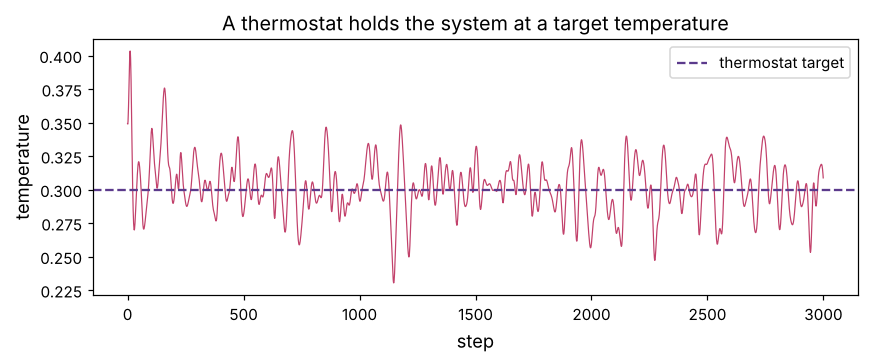

temperature settled to 0.30 (target 0.3)


In [4]:
# start hot, thermostat to a cool target: watch temperature relax
energies_t, temps_t, pos_t, vel_t = run(3000, thermostat=0.3)
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(temps_t, color="#c2416b", lw=0.8)
ax.axhline(0.3, color="#5b3a8c", ls="--", label="thermostat target")
ax.set_xlabel("step"); ax.set_ylabel("temperature"); ax.legend()
ax.set_title("A thermostat holds the system at a target temperature")
save_fig("thermostat"); plt.show()
R["T_final"] = f"{temps_t[-500:].mean():.2f}"
print(f"temperature settled to {temps_t[-500:].mean():.2f} (target 0.3)")

![Figure 12-3. With a thermostat, the temperature relaxes to and fluctuates around the target. Real thermostats (Nosé–Hoover, Langevin) are more careful but do the same job.](images/thermostat.png)

## Reading physics out of the trajectory

The output of MD is a **trajectory**: positions at every step. From it we measure physical quantities. Two classics: the **radial distribution function** $g(r)$, which shows how atoms arrange around each other (sharp peaks = ordered solid, broad = liquid), and the **mean-squared displacement**, whose slope gives the **diffusion coefficient** (prerequisite P1's $t = x^2/2D$).

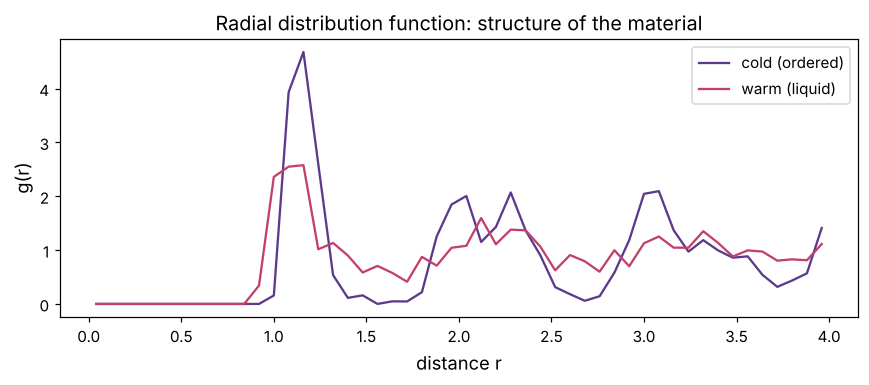

In [5]:
# radial distribution function at two temperatures: solid-like (cold) vs liquid-like (warm)
def rdf(positions, L, nbins=50, rmax=4.0):
    counts = np.zeros(nbins)
    for i in range(len(positions)):
        d = positions[i] - positions
        d -= L * np.round(d / L)
        r = np.sqrt((d ** 2).sum(1)); r = r[(r > 0) & (r < rmax)]
        counts += np.histogram(r, bins=nbins, range=(0, rmax))[0]
    edges = np.linspace(0, rmax, nbins + 1); centres = (edges[:-1] + edges[1:]) / 2
    shell = np.pi * (edges[1:] ** 2 - edges[:-1] ** 2)
    density = len(positions) / L ** 2
    return centres, counts / (len(positions) * density * shell)

fig, ax = plt.subplots(figsize=(8, 3.6))
for Ttarget, color, label in [(0.2, "#5b3a8c", "cold (ordered)"), (1.5, "#c2416b", "warm (liquid)")]:
    _, _, p, _ = run(3000, thermostat=Ttarget)
    c, g = rdf(p, L)
    ax.plot(c, g, color=color, label=label)
ax.set_xlabel("distance r"); ax.set_ylabel("g(r)"); ax.legend()
ax.set_title("Radial distribution function: structure of the material")
save_fig("rdf"); plt.show()

![Figure 12-4. The radial distribution g(r). Cold atoms show sharp peaks at regular spacings (an ordered lattice); warm atoms show a broad first peak and little beyond (a liquid). The same measurement on a protein simulation reveals solvation shells and packing.](images/rdf.png)

:::idea
Everything you just built is what real biomolecular MD does, with three big additions: (1) a realistic **force field** (AMBER, CHARMM, OPLS) with terms for covalent bonds, angles, dihedrals, electrostatics and van der Waals, carefully parameterised against experiment and quantum calculations; (2) explicit **water** molecules (often most of the atoms in the box); and (3) enormous scale, a protein–drug system is 50,000–500,000 atoms simulated for microseconds, which is billions of time steps. This is why MD runs on GPUs and special hardware (the Anton supercomputers), and why clever **enhanced-sampling** tricks exist to reach events that are too slow to see directly.
:::

## Why MD matters for drugs

A crystal structure shows one shape; MD shows the ensemble of shapes a protein actually visits, and that changes the drug-discovery picture:

| Use of MD | Why it matters |
|---|---|
| **Cryptic pockets** | pockets invisible in the crystal structure open up transiently; MD finds them |
| **Binding free energy** | simulating a drug in and out of the pocket estimates how tightly it binds (FEP, below) |
| **Induced fit** | the pocket reshapes around each drug; MD captures this flexibility |
| **Residence time** | how long a drug stays bound, often more predictive of efficacy than affinity |
| **Allostery** | how a drug binding at one site changes a distant site |
| **Water in the pocket** | ordered waters that a drug must displace or satisfy |

The most rigorous application is **free-energy perturbation** (FEP): by simulating a gradual transformation of one drug into a slightly different one, MD can predict the *difference* in binding affinity to within about 1 kcal/mol (prerequisite P2's 5.9 kJ/mol per 10-fold), accurate enough to rank candidate molecules before synthesising them. FEP is now used in real drug-discovery pipelines, and it rests entirely on the force-field-plus-integrator machinery you built here.

## Summary

| Idea | One line |
|---|---|
| Force field | the potential energy function U; force is its negative gradient |
| Lennard-Jones | repel when close, attract at range (van der Waals) |
| Velocity Verlet | the time-reversible, energy-conserving integrator |
| Energy conservation | the key correctness test; sets the time step |
| Temperature | average kinetic energy; a thermostat holds it fixed (NVT) |
| Trajectory analysis | g(r), diffusion, RMSD, and binding free energies |
| FEP | simulate a drug transformation to predict relative binding affinity |

:::check
1. In MD, how do you get the force on an atom from the potential energy? *(Force is minus the gradient of U.)*
2. Why does MD use velocity Verlet instead of simple Euler integration? *(It is time-reversible and conserves energy well; Euler drifts.)*
3. What is the single most important check that an MD simulation is correct? *(Total energy is conserved in an isolated (NVE) simulation.)*
4. What does temperature correspond to microscopically? *(The average kinetic energy of the atoms.)*
5. Name one thing MD reveals about a drug target that a crystal structure cannot. *(Flexibility / cryptic pockets / binding free energy / residence time.)*
:::

:::exercise
Measure diffusion. (a) Run the simulation at a warm (liquid) temperature and record each atom's position every few steps (accounting for periodic wrapping). (b) Compute the mean-squared displacement ⟨|r(t) − r(0)|²⟩ as a function of time. (c) Fit a line; its slope gives the diffusion coefficient D (in 2D, MSD = 4Dt). How does D change if you lower the temperature toward the solid regime, and why?
:::

<details><summary>Solution</summary>

In [6]:
def run_unwrapped(steps, Ttarget, sample=5):
    pos, vel = init(); F, _ = forces(pos)
    unwrapped = pos.copy(); traj = [unwrapped.copy()]
    for step in range(steps):
        vel += 0.5 * dt * F; old = pos.copy()
        pos = (pos + dt * vel) % L
        disp = pos - old; disp -= L * np.round(disp / L)          # undo periodic jumps
        unwrapped += disp
        F, _ = forces(pos); vel += 0.5 * dt * F
        KE = 0.5 * (vel ** 2).sum(); vel *= np.sqrt(1 + 0.05 * (Ttarget / (KE / N + 1e-9) - 1))
        if step % sample == 0: traj.append(unwrapped.copy())
    return np.array(traj)

for Ttarget in [0.3, 1.5]:
    traj = run_unwrapped(4000, Ttarget)
    msd = ((traj - traj[0]) ** 2).sum(2).mean(1)
    t_axis = np.arange(len(msd)) * 5 * dt
    D = np.polyfit(t_axis[len(t_axis)//2:], msd[len(t_axis)//2:], 1)[0] / 4
    print(f"temperature {Ttarget}: diffusion coefficient D = {D:.3f}")

temperature 0.3: diffusion coefficient D = 0.007


temperature 1.5: diffusion coefficient D = 0.082


Diffusion is far faster at high temperature: atoms have more kinetic energy to escape their neighbours' attraction, so the mean-squared displacement grows quickly and D is large. In the cold, solid-like regime, atoms are trapped in their lattice cages, MSD saturates instead of growing linearly, and D falls toward zero. This is exactly prerequisite P1's diffusion ($t \approx x^2/2D$) emerging from the atomic motion, and it is how MD predicts transport properties and how fast a drug can reach a buried pocket.

</details>